# MagiV2 Annotated Output Viewer

This notebook runs MagiV2 on a sequence and produces annotated page images showing:

- panels
- text boxes
- character boxes
- tail boxes
- same-character cluster links
- text → character links
- text → tail links
- optional OCR labels
- optional box IDs

Everything is local.

In [1]:
from pathlib import Path
from PIL import Image
import numpy as np
import torch
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from transformers import AutoModel

MODEL_PATH = r"C:\MODELS\magiv2"

model = AutoModel.from_pretrained(
    MODEL_PATH,
    trust_remote_code=True,
    local_files_only=True,
).cuda().eval()

print(type(model))

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.
c:\Users\ESHAAN\BYTE\Applied-Task\.venvAppliedTask\Lib\site-packages\torch\nn\modules\module.py:2593: UserWarning: for conv1.weight: copying from a non-meta parameter in the checkpoint to a meta parameter in the current model, which is a no-op. (Did you mean to pass `assign=True` to assign items in the state dictionary to their corresponding key in the module instead of copying them in place?)
  module._load_from_state_dict(
c:\Users\ESHAAN\BYTE\Applied-Task\.venvAppliedTask\Lib\site-packages\torch\nn\modules\batchnorm.py:141: UserWarning: for bn1.weight: copying from a non-meta parameter in the checkpoint to a meta parameter in the current model, which is a no-op. (D

<class 'transformers_modules.magiv2.modelling_magiv2.Magiv2Model'>


In [2]:
def read_image(path):
    with open(path, "rb") as f:
        return np.array(Image.open(f).convert("L").convert("RGB"))

## 1. Choose sequence

In [82]:
SEQUENCE_ROOT = Path(
    r"C:\Users\ESHAAN\BYTE\Applied-Task\Magi\TaskData\development\images\seq_2032620aa4e4ac7f"
)

PAGE_FILES = sorted(SEQUENCE_ROOT.glob("*.png"))
chapter_pages = [read_image(p) for p in PAGE_FILES]

print("Pages:", [p.name for p in PAGE_FILES])

Pages: ['01.png', '02.png', '03.png']


## 2. Run MagiV2

In [83]:
character_bank = {
    "images": [],
    "names": [],
}

with torch.no_grad():
    per_page_results = model.do_chapter_wide_prediction(
        chapter_pages,
        character_bank,
        use_tqdm=True,
        do_ocr=True,
    )

print(per_page_results[0].keys())

  0%|          | 0/1 [00:00<?, ?it/s]

100%|██████████| 1/1 [00:11<00:00, 11.74s/it]

dict_keys(['panels', 'texts', 'characters', 'tails', 'text_character_associations', 'text_tail_associations', 'character_cluster_labels', 'is_essential_text', 'ocr', 'character_names'])


In [ ]:
per_page_results[1].keys()

dict_keys(['panels', 'texts', 'characters', 'tails', 'text_character_associations', 'text_tail_associations', 'character_cluster_labels', 'is_essential_text', 'ocr', 'character_names'])

In [ ]:

per_page_results[0]['is_essential_text']

[False, True, True, False, True, False, True, False, True]

## 3. Custom visualizer

In [92]:
def center(box):
    x1, y1, x2, y2 = box
    return ((x1 + x2) / 2, (y1 + y2) / 2)


def draw_box(ax, box, edgecolor, label=None, linewidth=2, linestyle="-"):
    x1, y1, x2, y2 = box
    rect = patches.Rectangle(
        (x1, y1),
        x2 - x1,
        y2 - y1,
        linewidth=linewidth,
        edgecolor=edgecolor,
        facecolor="none",
        linestyle=linestyle,
    )
    ax.add_patch(rect)

    if label:
        ax.text(
            x1,
            max(0, y1 - 4),
            label,
            fontsize=8,
            bbox=dict(facecolor="black", alpha=0.65, edgecolor="none"),
            color="white",
        )


def annotate_magi_page(
    image,
    result,
    page_index=0,
    show_panels=True,
    show_texts=True,
    show_characters=True,
    show_tails=True,
    show_same_character=True,
    show_text_character=True,
    show_text_tail=True,
    show_ocr=True,
    show_ids=True,
    save_path=None,
):
    fig, ax = plt.subplots(figsize=(12, 18))
    ax.imshow(image)

    # Panels
    if show_panels:
        for i, box in enumerate(result["panels"]):
            label = f"PN{i+1}" if show_ids else None
            draw_box(ax, box, "green", label)

    # Text
    if show_texts:
        for i, box in enumerate(result["texts"]):
            essential = True
            if i < len(result.get("is_essential_text", [])):
                essential = bool(result["is_essential_text"][i])

            label = f"T{i+1}" if show_ids else ""
            if show_ocr and "ocr" in result and i < len(result["ocr"]):
                text = result["ocr"][i]
                if len(text) > 45:
                    text = text[:42] + "..."
                label = f"{label}: {text}" if label else text

            # essential text = red, non-essential = gray
            color = "red" if essential else "gray"
            draw_box(ax, box, color, label)

    # Characters
    if show_characters:
        cluster_labels = result.get("character_cluster_labels", [])
        for i, box in enumerate(result["characters"]):
            cluster = None
            if i < len(cluster_labels):
                cluster = int(cluster_labels[i]) + 1

            label = f"C{i+1}"
            if cluster is not None:
                label += f" / Cl{cluster}"

            draw_box(ax, box, "blue", label if show_ids else None)

    # Tails
    if show_tails:
        for i, box in enumerate(result["tails"]):
            label = f"TAIL{i+1}" if show_ids else None
            draw_box(ax, box, "purple", label)

    # Same-character links
    if show_same_character:
        cluster_labels = result.get("character_cluster_labels", [])
        groups = {}

        for i, label in enumerate(cluster_labels):
            groups.setdefault(int(label), []).append(i)

        for group in groups.values():
            if len(group) < 2:
                continue

            root = group[0]
            x1, y1 = center(result["characters"][root])

            for j in group[1:]:
                x2, y2 = center(result["characters"][j])
                ax.plot([x1, x2], [y1, y2], linewidth=2)

    # Text -> character
    if show_text_character:
        for text_idx, char_idx in result["text_character_associations"]:
            if text_idx >= len(result["texts"]) or char_idx >= len(result["characters"]):
                continue

            x1, y1 = center(result["texts"][text_idx])
            x2, y2 = center(result["characters"][char_idx])

            ax.plot(
                [x1, x2],
                [y1, y2],
                linestyle="--",
                linewidth=2,
            )

            if show_ids:
                mx, my = (x1+x2)/2, (y1+y2)/2
                ax.text(
                    mx, my,
                    f"T{text_idx+1}->C{char_idx+1}",
                    fontsize=7,
                    bbox=dict(facecolor="white", alpha=0.7, edgecolor="none"),
                )

    # Text -> tail
    if show_text_tail:
        for text_idx, tail_idx in result["text_tail_associations"]:
            if text_idx >= len(result["texts"]) or tail_idx >= len(result["tails"]):
                continue

            x1, y1 = center(result["texts"][text_idx])
            x2, y2 = center(result["tails"][tail_idx])

            ax.plot(
                [x1, x2],
                [y1, y2],
                linestyle=":",
                linewidth=2,
            )

            if show_ids:
                mx, my = (x1+x2)/2, (y1+y2)/2
                ax.text(
                    mx, my,
                    f"T{text_idx+1}->TAIL{tail_idx+1}",
                    fontsize=7,
                    bbox=dict(facecolor="white", alpha=0.7, edgecolor="none"),
                )

    ax.set_title(f"MagiV2 annotations - page {page_index + 1}")
    ax.axis("off")
    plt.tight_layout()

    if save_path is not None:
        plt.savefig(save_path, bbox_inches="tight", pad_inches=0.05, dpi=150)

    plt.show()

## 4. Show one page with ALL MagiV2 annotations

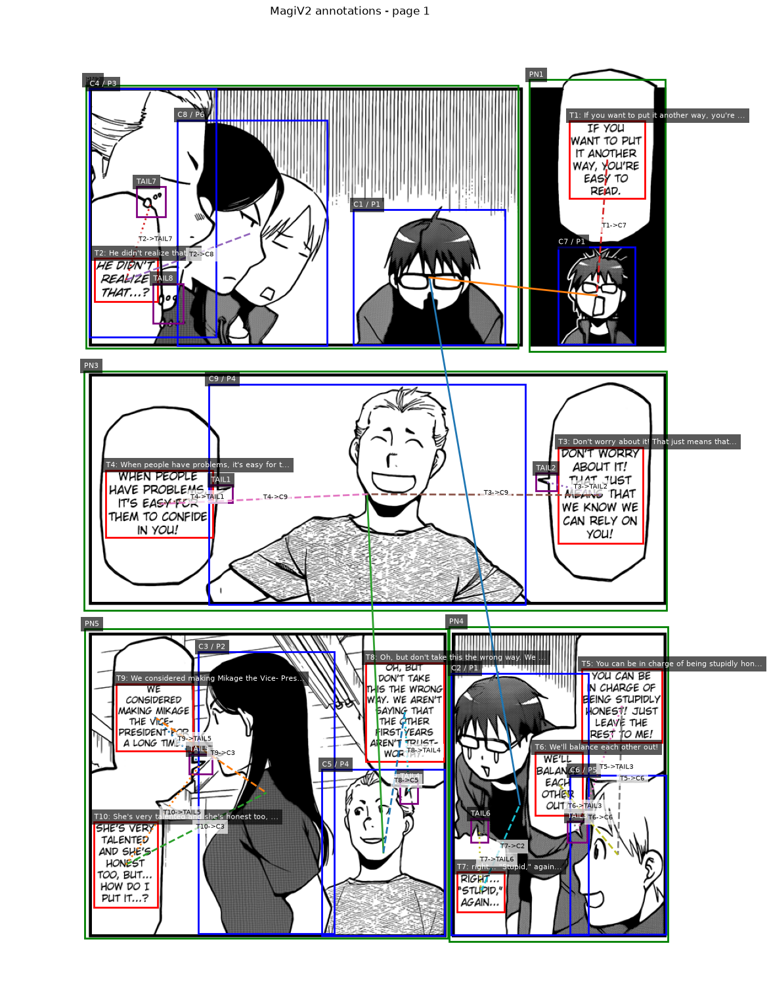

In [22]:
PAGE_INDEX = 0

annotate_magi_page(
    chapter_pages[PAGE_INDEX],
    per_page_results[PAGE_INDEX],
    page_index=PAGE_INDEX,
    show_panels=True,
    show_texts=True,
    show_characters=True,
    show_tails=True,
    show_same_character=True,
    show_text_character=True,
    show_text_tail=True,
    show_ocr=True,
    show_ids=True,
)

## 5. Save annotated images for the whole sequence

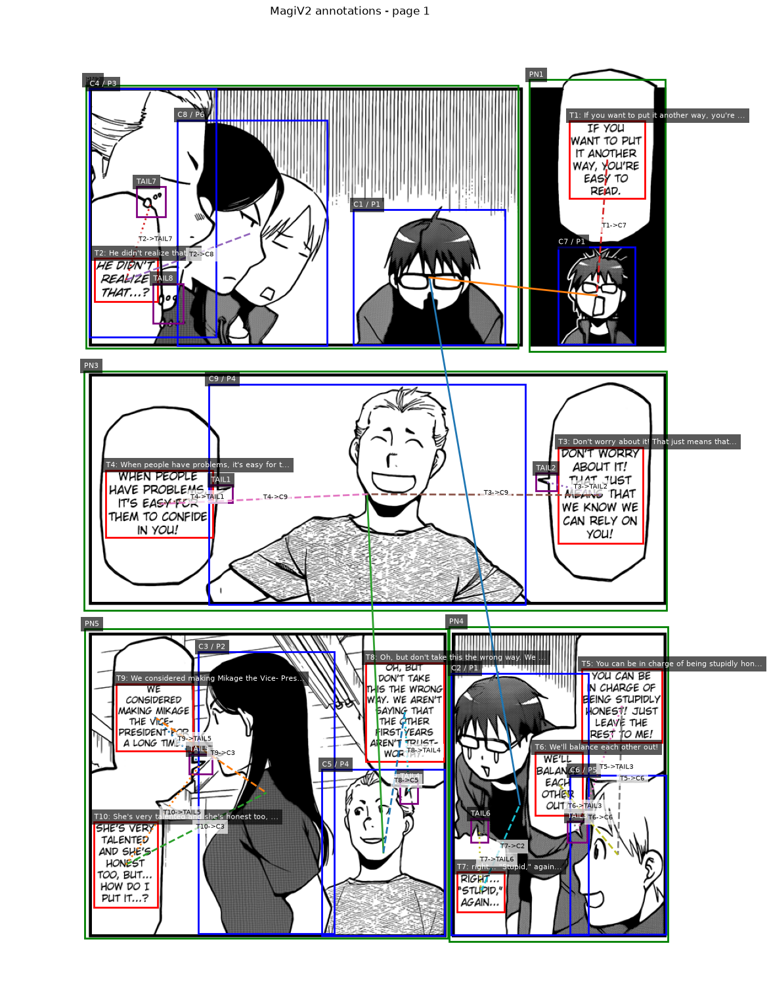

saved: C:\Users\ESHAAN\BYTE\Applied-Task\Magi\TaskData\development\images\seq_7db7a000adeceacf\magiv2_annotated\page_01_annotated.png


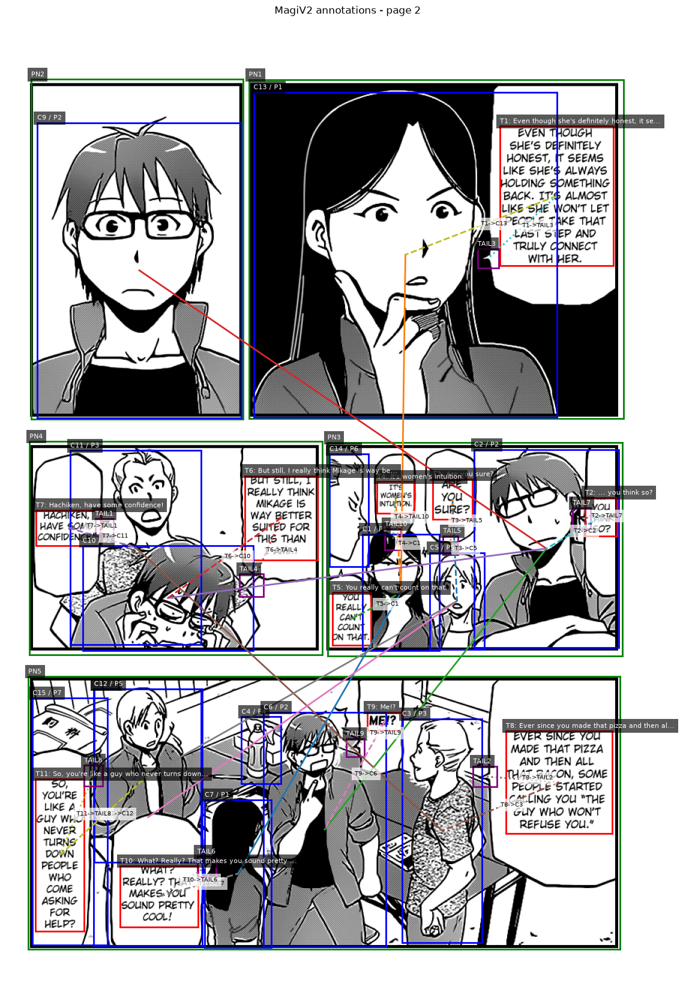

saved: C:\Users\ESHAAN\BYTE\Applied-Task\Magi\TaskData\development\images\seq_7db7a000adeceacf\magiv2_annotated\page_02_annotated.png


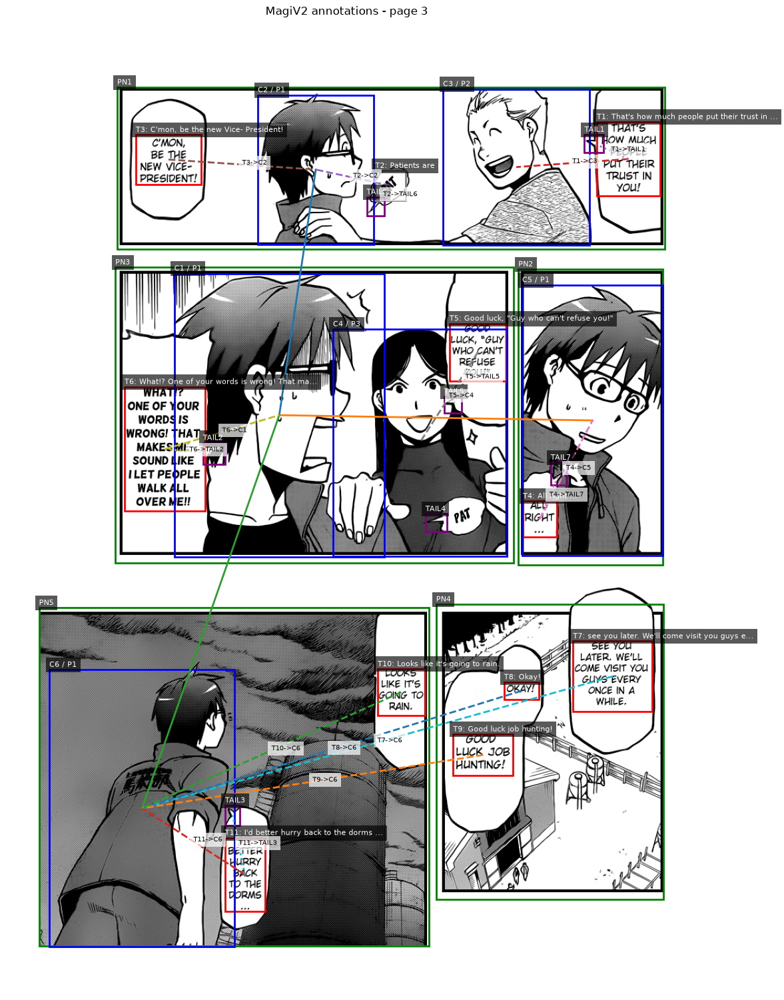

saved: C:\Users\ESHAAN\BYTE\Applied-Task\Magi\TaskData\development\images\seq_7db7a000adeceacf\magiv2_annotated\page_03_annotated.png


In [23]:
OUTPUT_DIR = SEQUENCE_ROOT / "magiv2_annotated"
OUTPUT_DIR.mkdir(exist_ok=True)

for i, (page, result) in enumerate(zip(chapter_pages, per_page_results)):
    output_path = OUTPUT_DIR / f"page_{i+1:02d}_annotated.png"

    annotate_magi_page(
        page,
        result,
        page_index=i,
        show_panels=True,
        show_texts=True,
        show_characters=True,
        show_tails=True,
        show_same_character=True,
        show_text_character=True,
        show_text_tail=True,
        show_ocr=True,
        show_ids=True,
        save_path=output_path,
    )

    print("saved:", output_path)

## 6. Easy presets

Use these when you only want one type of MagiV2 output.

In [94]:
def show_only(kind, page_index=0):
    flags = dict(
        show_panels=False,
        show_texts=False,
        show_characters=False,
        show_tails=False,
        show_same_character=False,
        show_text_character=False,
        show_text_tail=False,
        show_ocr=False,
        show_ids=False,
    )

    mapping = {
        "panels": ["show_panels"],
        "texts": ["show_texts"],
        "characters": ["show_characters"],
        "tails": ["show_tails"],
        "same_character": ["show_characters", "show_same_character"],
        "text_character": ["show_texts", "show_characters", "show_text_character"],
        "text_tail": ["show_texts", "show_tails", "show_text_tail"],
        "ocr": ["show_texts", "show_ocr"],
        "all": [
            "show_panels",
            "show_texts",
            "show_characters",
            "show_tails",
            "show_same_character",
            "show_text_character",
            "show_text_tail",
            "show_ocr",
        ],
    }

    if kind not in mapping:
        raise ValueError(f"Choose one of: {list(mapping)}")

    for key in mapping[kind]:
        flags[key] = True

    annotate_magi_page(
        chapter_pages[page_index],
        per_page_results[page_index],
        page_index=page_index,
        **flags,
    )

In [101]:
# Examples:

# show_only("all", page_index=0)

# show_only("characters", page_index=0)
# show_only("same_character", page_index=0)
# show_only("text_character", page_index=0)
# show_only("text_tail", page_index=0)
# show_only("tails", page_index=0)
# show_only("ocr", page_index=0)

## CROSS-PAGE-CHAR-SIMILARITY

In [ ]:
import torch
import pandas as pd

# Character boxes detected by MagiV2
character_boxes = [
    result["characters"]
    for result in per_page_results
]

with torch.no_grad():
    embeddings_per_page = model.predict_crop_embeddings(
        chapter_pages,
        character_boxes,
    )

# Normalize so dot product = cosine similarity
embeddings_per_page = [
    torch.nn.functional.normalize(x, p=2, dim=1)
    if len(x) > 0 else x
    for x in embeddings_per_page
]

for page_idx, emb in enumerate(embeddings_per_page):
    print(
        f"Page {page_idx + 1}: "
        f"{len(emb)} characters, embedding shape = {tuple(emb.shape)}"
    )

Page 1: 9 characters, embedding shape = (9, 768)
Page 2: 15 characters, embedding shape = (15, 768)
Page 3: 6 characters, embedding shape = (6, 768)


In [ ]:
def cosine_matrix(page_a, page_b):
    A = embeddings_per_page[page_a]
    B = embeddings_per_page[page_b]

    if len(A) == 0 or len(B) == 0:
        return None

    return A @ B.T


def show_similarity_matrix(page_a, page_b):
    sims = cosine_matrix(page_a, page_b)

    if sims is None:
        print("No characters on one of the pages.")
        return

    df = pd.DataFrame(
        sims.cpu().numpy(),
        index=[
            f"P{page_a+1}:C{i+1}"
            for i in range(sims.shape[0])
        ],
        columns=[
            f"P{page_b+1}:C{i+1}"
            for i in range(sims.shape[1])
        ],
    )

    return df.round(3)

In [ ]:
df = show_similarity_matrix(0, 1)

In [75]:
def best_matches(page_a, page_b):
    sims = cosine_matrix(page_a, page_b)
    best_match = {}
    if sims is None:
        return

    for i in range(sims.shape[0]):
        best_j = sims[i].argmax().item()
        score = sims[i, best_j].item()

        # print(
        #     f"P{page_a+1}:C{i+1}"
        #     f" -> "
        #     f"P{page_b+1}:C{best_j+1}"
        #     f" | cosine={score:.3f}"
        # )
        best_match[f"P{page_a+1}:C{i+1}"] = {"match" : f"P{page_b+1}:C{best_j+1}", "cosine" : score}
    return best_match
a = best_matches(1,0)
a
# best_matches(1,2)

{'P2:C1': {'match': 'P1:C3', 'cosine': 0.839594841003418},
 'P2:C2': {'match': 'P1:C7', 'cosine': 0.8955718278884888},
 'P2:C3': {'match': 'P1:C9', 'cosine': 0.8778837323188782},
 'P2:C4': {'match': 'P1:C9', 'cosine': 0.4654075503349304},
 'P2:C5': {'match': 'P1:C6', 'cosine': 0.7659403085708618},
 'P2:C6': {'match': 'P1:C7', 'cosine': 0.9016721248626709},
 'P2:C7': {'match': 'P1:C3', 'cosine': 0.9138832688331604},
 'P2:C8': {'match': 'P1:C6', 'cosine': 0.794068455696106},
 'P2:C9': {'match': 'P1:C7', 'cosine': 0.9163054823875427},
 'P2:C10': {'match': 'P1:C7', 'cosine': 0.9062365889549255},
 'P2:C11': {'match': 'P1:C5', 'cosine': 0.8998408317565918},
 'P2:C12': {'match': 'P1:C6', 'cosine': 0.8436264395713806},
 'P2:C13': {'match': 'P1:C3', 'cosine': 0.9363231062889099},
 'P2:C14': {'match': 'P1:C4', 'cosine': 0.9216442704200745},
 'P2:C15': {'match': 'P1:C4', 'cosine': 0.6732085943222046}}

In [62]:
def clusterize(page_numbers, per_page_results, threshold=0.75):
    """
    page_numbers example: [0, 1, 2]

    Uses all pairwise page comparisons and merges
    mutual matches into sequence-level identities.

    Returns:
    {
        "S1": ["P1:C1", "P2:C3", "P3:C2"],
        "S2": ["P1:C2", "P3:C1"],
        ...
    }
    """

    # ---------- union find ----------
    parent = {}

    def find(x):
        if x not in parent:
            parent[x] = x

        if parent[x] != x:
            parent[x] = find(parent[x])

        return parent[x]

    def union(a, b):
        ra = find(a)
        rb = find(b)

        if ra != rb:
            parent[rb] = ra

    # ---------- register ALL characters ----------
    for page in page_numbers:
        n_chars = len(per_page_results[page]["characters"])

        for i in range(n_chars):
            char_id = f"P{page+1}:C{i+1}"
            parent[char_id] = char_id

    # ---------- compare every pair of pages ----------
    for i in range(len(page_numbers)):
        for j in range(i + 1, len(page_numbers)):
            page_a = page_numbers[i]
            page_b = page_numbers[j]

            matches_ab = best_matches(page_a, page_b)
            matches_ba = best_matches(page_b, page_a)

            if matches_ab is None or matches_ba is None:
                continue

            for char_a, info_ab in matches_ab.items():
                char_b = info_ab["match"]
                score_ab = info_ab["cosine"]

                # Does B also choose A as its best match?
                if char_b not in matches_ba:
                    continue

                info_ba = matches_ba[char_b]

                mutual = info_ba["match"] == char_a
                score_ba = info_ba["cosine"]

                if (
                    mutual
                    and score_ab >= threshold
                    and score_ba >= threshold
                ):
                    union(char_a, char_b)

    # ---------- collect clusters ----------
    groups = {}

    for char_id in parent:
        root = find(char_id)
        groups.setdefault(root, []).append(char_id)

    # ---------- rename as S1, S2, ... ----------
    identified_char = {}

    for idx, members in enumerate(groups.values(), start=1):
        identified_char[f"S{idx}"] = sorted(members)

    return identified_char

In [70]:
identified_char = clusterize(
    per_page_results=per_page_results,
    page_numbers=[0, 1, 2],
    threshold=0.0
)

identified_char

{'S1': ['P1:C1'],
 'S2': ['P1:C2', 'P2:C6', 'P3:C2'],
 'S3': ['P1:C3', 'P2:C13', 'P3:C4'],
 'S4': ['P1:C4', 'P2:C14'],
 'S5': ['P1:C5', 'P1:C9', 'P2:C11', 'P3:C3'],
 'S6': ['P1:C6', 'P2:C12'],
 'S7': ['P1:C7', 'P2:C9', 'P3:C5'],
 'S8': ['P1:C8'],
 'S9': ['P2:C1'],
 'S10': ['P2:C2'],
 'S11': ['P2:C3'],
 'S12': ['P2:C4'],
 'S13': ['P2:C5'],
 'S14': ['P2:C7'],
 'S15': ['P2:C8'],
 'S16': ['P2:C10'],
 'S17': ['P2:C15'],
 'S18': ['P3:C1'],
 'S19': ['P3:C6']}

In [76]:
for p in [0,1,2]:
    print(
        f"Page {p+1}:",
        len(per_page_results[p]["characters"])
    )

print("Total detections:",
      sum(len(per_page_results[p]["characters"]) for p in [0,1,2]))

print("Sequence identities:", len(identified_char))

Page 1: 9
Page 2: 15
Page 3: 6
Total detections: 30
Sequence identities: 19


## VIEW CHAR SETS

In [58]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import matplotlib.cm as cm

def parse_char_ref(ref):
    # "P2:C3" -> page_idx=1, char_idx=2
    page_part, char_part = ref.split(":")
    page_idx = int(page_part[1:]) - 1
    char_idx = int(char_part[1:]) - 1
    return page_idx, char_idx


def build_s_color_map(identified_char):
    cmap = plt.get_cmap("tab20", max(len(identified_char), 1))
    s_to_color = {}

    for i, s_id in enumerate(sorted(identified_char.keys())):
        s_to_color[s_id] = cmap(i)

    return s_to_color


def annotate_sequence_identities(
    chapter_pages,
    per_page_results,
    identified_char,
    show_text_char=False,
    show_page_local_labels=False,
    save_dir=None,
):
    s_to_color = build_s_color_map(identified_char)

    # reverse map: "P1:C2" -> "S3"
    char_to_s = {}
    for s_id, members in identified_char.items():
        for ref in members:
            char_to_s[ref] = s_id

    for page_idx, (image, result) in enumerate(zip(chapter_pages, per_page_results)):
        fig, ax = plt.subplots(figsize=(12, 18))
        ax.imshow(image)

        # Draw character boxes with S-color
        for char_idx, box in enumerate(result["characters"]):
            ref = f"P{page_idx+1}:C{char_idx+1}"

            if ref in char_to_s:
                s_id = char_to_s[ref]
                color = s_to_color[s_id]
                label = s_id
                if show_page_local_labels and "character_cluster_labels" in result:
                    label += f" / P{int(result['character_cluster_labels'][char_idx]) + 1}"
            else:
                color = "white"
                label = "UNMATCHED"

            x1, y1, x2, y2 = box
            rect = patches.Rectangle(
                (x1, y1),
                x2 - x1,
                y2 - y1,
                linewidth=3,
                edgecolor=color,
                facecolor="none"
            )
            ax.add_patch(rect)

            ax.text(
                x1,
                max(0, y1 - 5),
                label,
                fontsize=9,
                color="white",
                bbox=dict(facecolor=color, alpha=0.8, edgecolor="none")
            )

        # Optional: draw text -> character links using same S-color
        if show_text_char and "text_character_associations" in result:
            for text_idx, char_idx in result["text_character_associations"]:
                if text_idx >= len(result["texts"]) or char_idx >= len(result["characters"]):
                    continue

                ref = f"P{page_idx+1}:C{char_idx+1}"
                color = s_to_color[char_to_s[ref]] if ref in char_to_s else "white"

                tx1, ty1, tx2, ty2 = result["texts"][text_idx]
                cx1, cy1, cx2, cy2 = result["characters"][char_idx]

                text_center = ((tx1 + tx2) / 2, (ty1 + ty2) / 2)
                char_center = ((cx1 + cx2) / 2, (cy1 + cy2) / 2)

                ax.plot(
                    [text_center[0], char_center[0]],
                    [text_center[1], char_center[1]],
                    linestyle="--",
                    linewidth=2,
                    color=color
                )

        ax.set_title(f"Sequence identities - page {page_idx+1}: {PAGE_FILES[page_idx].name}")
        ax.axis("off")
        plt.tight_layout()

        if save_dir is not None:
            save_dir.mkdir(exist_ok=True, parents=True)
            out_path = save_dir / f"page_{page_idx+1:02d}_S_identities.png"
            plt.savefig(out_path, bbox_inches="tight", pad_inches=0.05, dpi=150)
            print("saved:", out_path)

        plt.show()

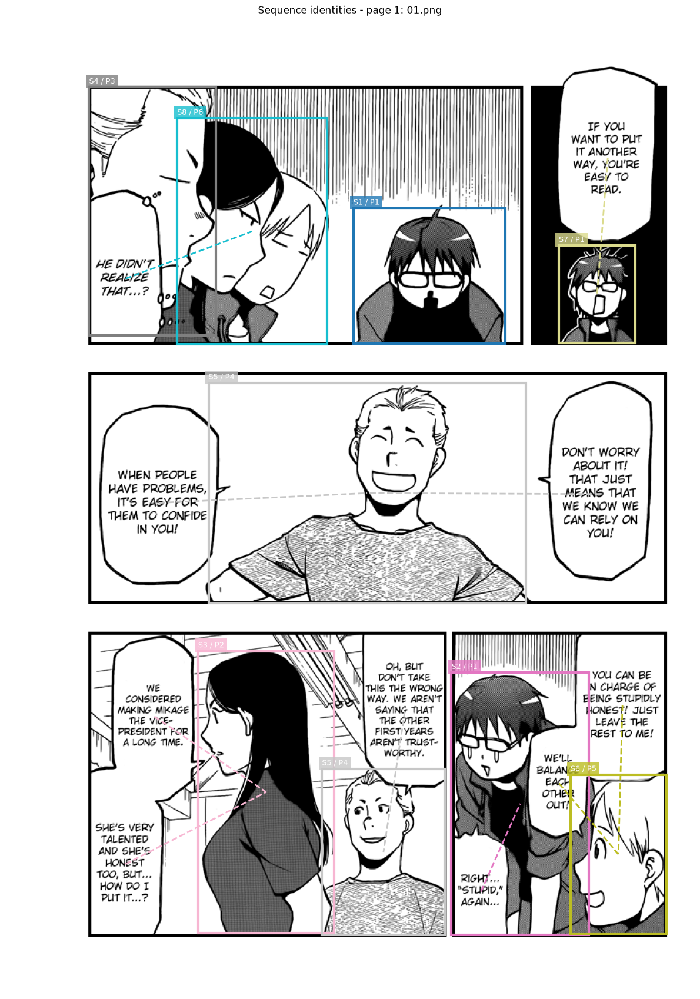

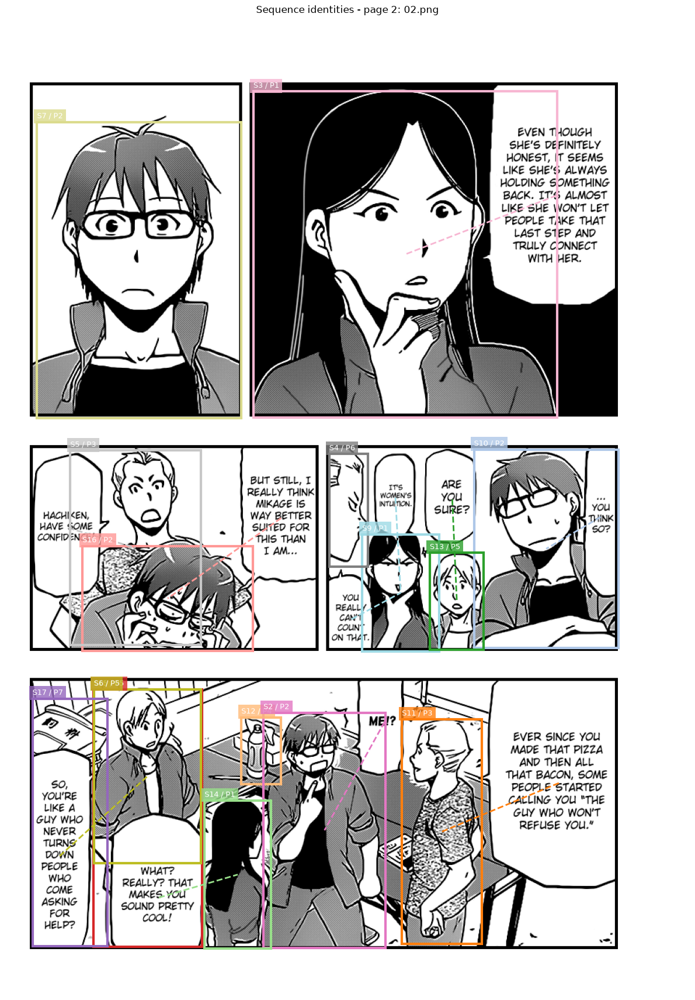

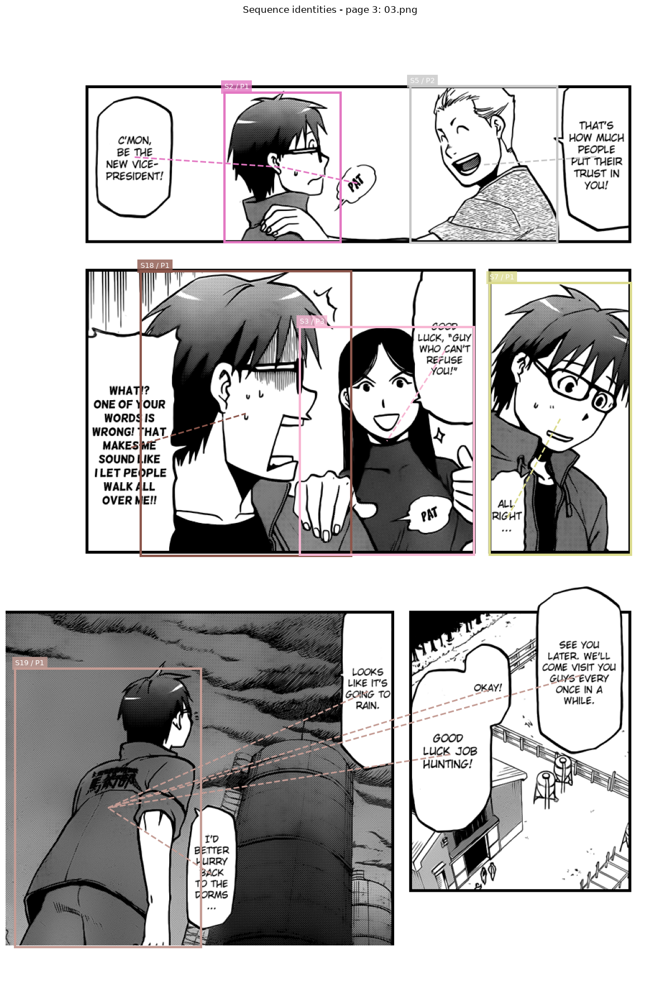

In [59]:
annotate_sequence_identities(
    chapter_pages=chapter_pages,
    per_page_results=per_page_results,
    identified_char=identified_char,
    show_text_char=True,          # optional
    show_page_local_labels=True,  # optional
)

SAVING

saved: C:\Users\ESHAAN\BYTE\Applied-Task\Magi\TaskData\development\images\seq_7db7a000adeceacf\sequence_identity_annotations\page_01_S_identities.png


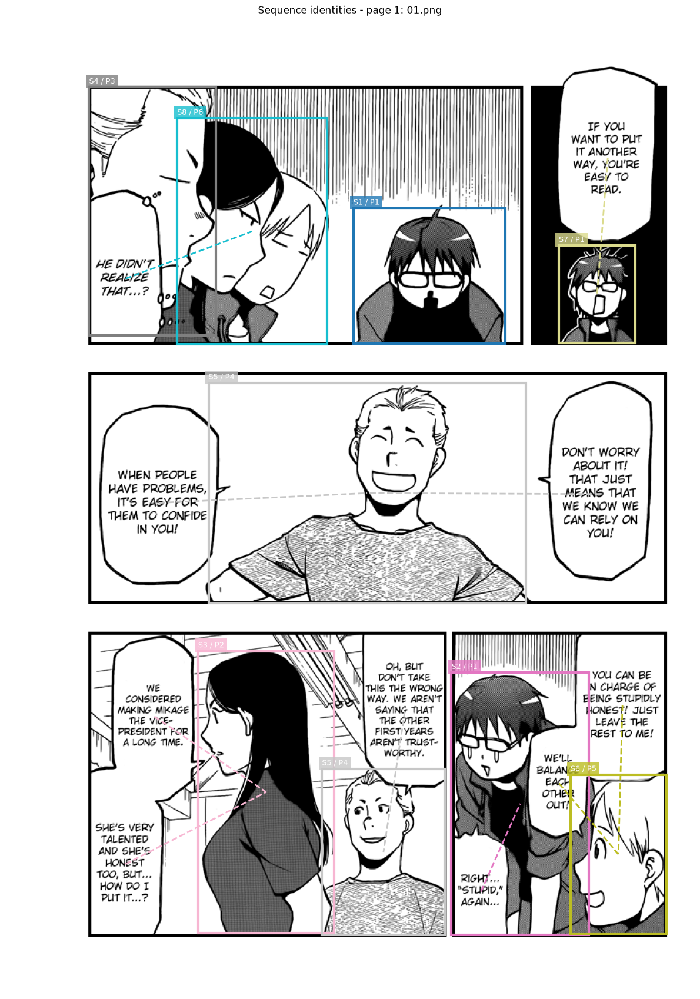

saved: C:\Users\ESHAAN\BYTE\Applied-Task\Magi\TaskData\development\images\seq_7db7a000adeceacf\sequence_identity_annotations\page_02_S_identities.png


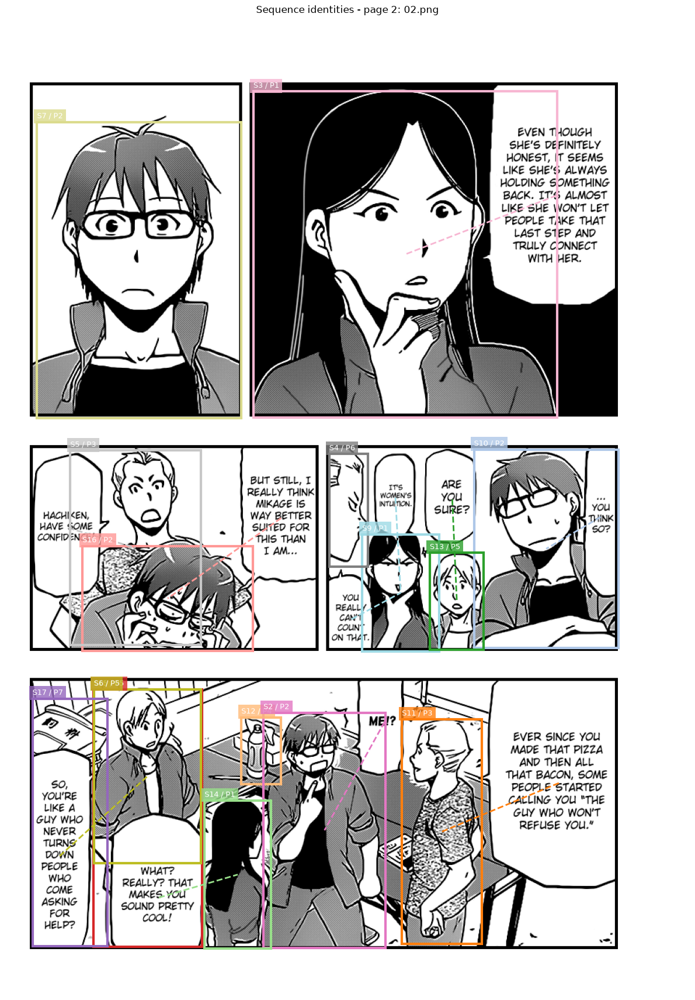

saved: C:\Users\ESHAAN\BYTE\Applied-Task\Magi\TaskData\development\images\seq_7db7a000adeceacf\sequence_identity_annotations\page_03_S_identities.png


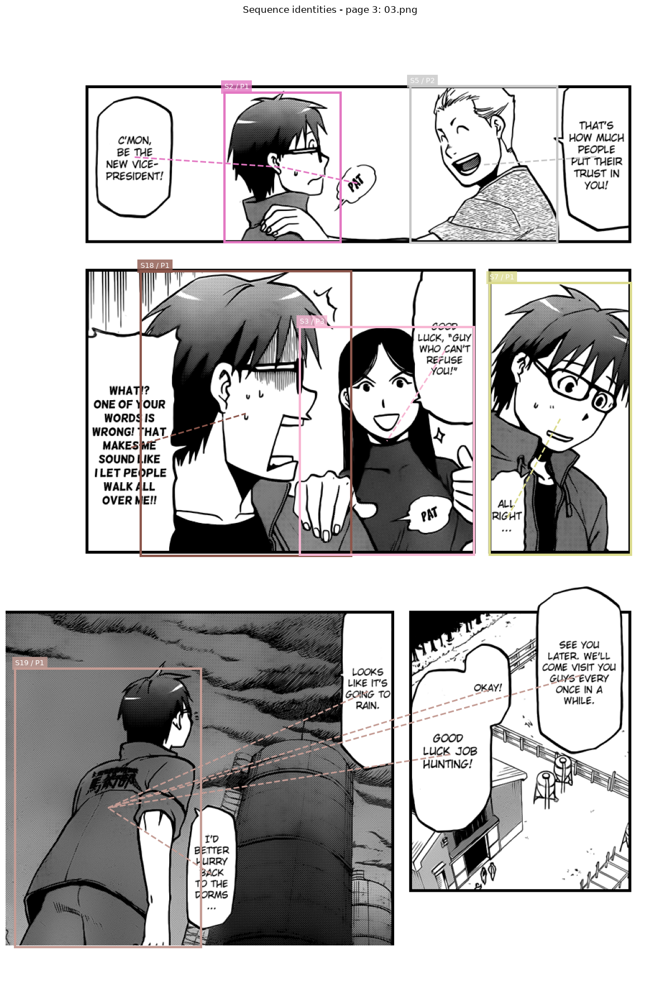

In [60]:
from pathlib import Path

SAVE_DIR = SEQUENCE_ROOT / "sequence_identity_annotations"

annotate_sequence_identities(
    chapter_pages=chapter_pages,
    per_page_results=per_page_results,
    identified_char=identified_char,
    show_text_char=True,
    show_page_local_labels=True,
    save_dir=SAVE_DIR,
)

# TEMP


In [77]:
import torch


# ---------------------------------------------------------
# Naming
#
# PG1:C1   = character detection 1 on page 1
# PG1:CL1  = page-local MagiV2 character cluster 1
# S1       = sequence-wide identity
# ---------------------------------------------------------


def get_page_clusters(page_idx, per_page_results):
    """
    Convert MagiV2 character_cluster_labels into:

    {
        "PG1:CL1": [0, 3, 6],   # character indices C1, C4, C7
        "PG1:CL2": [1]
    }
    """

    labels = per_page_results[page_idx]["character_cluster_labels"]

    clusters = {}

    for char_idx, cluster_idx in enumerate(labels):
        cluster_id = f"PG{page_idx + 1}:CL{int(cluster_idx) + 1}"

        if cluster_id not in clusters:
            clusters[cluster_id] = []

        clusters[cluster_id].append(char_idx)

    return clusters

In [78]:
def cluster_similarity(
    page_idx,
    char_indices,
    sequence_identity,
    embeddings_per_page,
):
    """
    Compare one page-local cluster against an existing S identity.

    Score =
        maximum cosine similarity between ANY character appearance
        in the current CL and ANY appearance already inside S.

    Returns:
        best_score
        best_pair
    """

    best_score = -1.0
    best_pair = None

    current_embeddings = embeddings_per_page[page_idx]

    for current_char_idx in char_indices:

        current_embedding = current_embeddings[current_char_idx]

        for member in sequence_identity["members"]:

            old_page_idx = member["page_idx"]
            old_char_idx = member["char_idx"]

            old_embedding = embeddings_per_page[old_page_idx][old_char_idx]

            score = torch.dot(
                current_embedding,
                old_embedding
            ).item()

            if score > best_score:
                best_score = score

                best_pair = {
                    "current": f"PG{page_idx+1}:C{current_char_idx+1}",
                    "existing": f"PG{old_page_idx+1}:C{old_char_idx+1}",
                }

    return best_score, best_pair

In [79]:
def clusterize(
    page_numbers,
    per_page_results,
    embeddings_per_page,
    threshold=0.80,
):
    """
    Sequential cross-page identity clustering.

    Matching unit:
        page-local MagiV2 cluster (CL)

    Similarity:
        best member-to-member cosine similarity

    Returns:
        identified_char
    """

    identified_char = {}

    next_s_id = 1

    # =====================================================
    # PAGE 1
    # Initialize one S identity for every local CL
    # =====================================================

    first_page = page_numbers[0]

    first_clusters = get_page_clusters(
        first_page,
        per_page_results
    )

    for cluster_id, char_indices in first_clusters.items():

        s_id = f"S{next_s_id}"
        next_s_id += 1

        identified_char[s_id] = {
            "clusters": [cluster_id],
            "members": []
        }

        for char_idx in char_indices:

            identified_char[s_id]["members"].append({
                "page_idx": first_page,
                "char_idx": char_idx,
                "char_id": f"PG{first_page+1}:C{char_idx+1}",
                "cluster_id": cluster_id,
            })


    # =====================================================
    # Remaining pages
    # =====================================================

    for page_idx in page_numbers[1:]:

        current_clusters = get_page_clusters(
            page_idx,
            per_page_results
        )

        # potential matches:
        #
        # score,
        # cluster_id,
        # S identity,
        # strongest individual C-C pair
        candidates = []

        for cluster_id, char_indices in current_clusters.items():

            for s_id, sequence_identity in identified_char.items():

                score, best_pair = cluster_similarity(
                    page_idx,
                    char_indices,
                    sequence_identity,
                    embeddings_per_page,
                )

                if score >= threshold:

                    candidates.append({
                        "score": score,
                        "cluster_id": cluster_id,
                        "s_id": s_id,
                        "best_pair": best_pair,
                    })


        # strongest evidence first
        candidates.sort(
            key=lambda x: x["score"],
            reverse=True
        )


        # =================================================
        # One CL can match only one S
        # One S can receive only one CL from this page
        # =================================================

        used_clusters = set()
        used_s = set()

        accepted_matches = {}

        for candidate in candidates:

            cluster_id = candidate["cluster_id"]
            s_id = candidate["s_id"]

            if cluster_id in used_clusters:
                continue

            if s_id in used_s:
                continue

            accepted_matches[cluster_id] = candidate

            used_clusters.add(cluster_id)
            used_s.add(s_id)


        # =================================================
        # Apply matches
        # =================================================

        for cluster_id, char_indices in current_clusters.items():

            # Existing identity
            if cluster_id in accepted_matches:

                match = accepted_matches[cluster_id]
                s_id = match["s_id"]

                identified_char[s_id]["clusters"].append(
                    cluster_id
                )

                for char_idx in char_indices:

                    identified_char[s_id]["members"].append({
                        "page_idx": page_idx,
                        "char_idx": char_idx,
                        "char_id": f"PG{page_idx+1}:C{char_idx+1}",
                        "cluster_id": cluster_id,
                    })


            # No good match -> new sequence identity
            else:

                s_id = f"S{next_s_id}"
                next_s_id += 1

                identified_char[s_id] = {
                    "clusters": [cluster_id],
                    "members": []
                }

                for char_idx in char_indices:

                    identified_char[s_id]["members"].append({
                        "page_idx": page_idx,
                        "char_idx": char_idx,
                        "char_id": f"PG{page_idx+1}:C{char_idx+1}",
                        "cluster_id": cluster_id,
                    })


        # Show what happened for this page
        print(f"\n===== PAGE {page_idx + 1} =====")

        for cluster_id in current_clusters:

            if cluster_id in accepted_matches:

                m = accepted_matches[cluster_id]

                print(
                    f"{cluster_id} -> {m['s_id']} "
                    f"| cosine={m['score']:.3f} "
                    f"| {m['best_pair']['current']} "
                    f"<-> {m['best_pair']['existing']}"
                )

            else:
                # find newly created S
                for s_id, data in identified_char.items():
                    if cluster_id in data["clusters"]:
                        print(
                            f"{cluster_id} -> {s_id} "
                            f"| NEW IDENTITY"
                        )
                        break


    return identified_char

In [80]:
identified_char = clusterize(
    page_numbers=[0, 1, 2],
    per_page_results=per_page_results,
    embeddings_per_page=embeddings_per_page,
    threshold=0.80,
)


===== PAGE 2 =====
PG2:CL1 -> S2 | cosine=0.936 | PG2:C13 <-> PG1:C3
PG2:CL2 -> S1 | cosine=0.916 | PG2:C9 <-> PG1:C7
PG2:CL3 -> S4 | cosine=0.900 | PG2:C11 <-> PG1:C5
PG2:CL4 -> S7 | NEW IDENTITY
PG2:CL5 -> S5 | cosine=0.844 | PG2:C12 <-> PG1:C6
PG2:CL6 -> S3 | cosine=0.922 | PG2:C14 <-> PG1:C4
PG2:CL7 -> S8 | NEW IDENTITY

===== PAGE 3 =====
PG3:CL1 -> S1 | cosine=0.968 | PG3:C2 <-> PG1:C2
PG3:CL2 -> S4 | cosine=0.932 | PG3:C3 <-> PG1:C9
PG3:CL3 -> S2 | cosine=0.931 | PG3:C4 <-> PG1:C3


In [81]:
for s_id, data in identified_char.items():

    print(f"\n{s_id}")

    print(" clusters:")
    for x in data["clusters"]:
        print("   ", x)

    print(" characters:")
    for x in data["members"]:
        print("   ", x["char_id"])


S1
 clusters:
    PG1:CL1
    PG2:CL2
    PG3:CL1
 characters:
    PG1:C1
    PG1:C2
    PG1:C7
    PG2:C2
    PG2:C6
    PG2:C9
    PG2:C10
    PG3:C1
    PG3:C2
    PG3:C5
    PG3:C6

S2
 clusters:
    PG1:CL2
    PG2:CL1
    PG3:CL3
 characters:
    PG1:C3
    PG2:C1
    PG2:C7
    PG2:C13
    PG3:C4

S3
 clusters:
    PG1:CL3
    PG2:CL6
 characters:
    PG1:C4
    PG2:C14

S4
 clusters:
    PG1:CL4
    PG2:CL3
    PG3:CL2
 characters:
    PG1:C5
    PG1:C9
    PG2:C3
    PG2:C11
    PG3:C3

S5
 clusters:
    PG1:CL5
    PG2:CL5
 characters:
    PG1:C6
    PG2:C5
    PG2:C8
    PG2:C12

S6
 clusters:
    PG1:CL6
 characters:
    PG1:C8

S7
 clusters:
    PG2:CL4
 characters:
    PG2:C4

S8
 clusters:
    PG2:CL7
 characters:
    PG2:C15
